# Explaining Customer Clusters

This notebook describes the customer groups saved by K-Means and Ward-linkage Hierarchical Clustering in Experiments 1 and 2. It uses the saved assignments rather than fitting new clusters, so the profiles describe the actual experiment results.

Experiment 1 uses Annual Income and Spending Score; Experiment 2 adds Age. The K-Means notebooks use five clusters in both experiments. The Hierarchical notebooks use five clusters in Experiment 1 and six in Experiment 2. Cluster numbers are algorithm labels, not ranked categories.

## 1. Load and Validate the Experiment Results

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

FEATURES = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
RESULT_FILES = {
    "K-Means Experiment 1": ("kmeans_exp1_result.csv", "Cluster"),
    "K-Means Experiment 2": ("kmeans_exp2_result.csv", "Cluster"),
    "Hierarchical Experiment 1": ("hierarchical_exp1_result.csv", "Hierarchical_Cluster"),
    "Hierarchical Experiment 2": ("hierarchical_exp2_result.csv", "Hierarchical_Cluster"),
}

customers = pd.read_csv("Mall_Customers.csv")
assert customers["CustomerID"].is_unique, "CustomerID must be unique in the source dataset."
assignments = {}

for experiment, (file_name, label_column) in RESULT_FILES.items():
    result = pd.read_csv(file_name)
    required_columns = {"CustomerID", label_column, *FEATURES}
    missing_columns = required_columns.difference(result.columns)
    assert not missing_columns, f"{file_name} is missing columns: {sorted(missing_columns)}"
    assert result["CustomerID"].is_unique, f"CustomerID is repeated in {file_name}."
    assert set(result["CustomerID"]) == set(customers["CustomerID"]), (
        f"Customer IDs in {file_name} do not match Mall_Customers.csv."
    )

    aligned = result.sort_values("CustomerID").reset_index(drop=True)
    source = customers.sort_values("CustomerID").reset_index(drop=True)
    assert np.array_equal(aligned[FEATURES].to_numpy(), source[FEATURES].to_numpy()), (
        f"Feature values in {file_name} do not match Mall_Customers.csv."
    )
    assignments[experiment] = aligned[["CustomerID", *FEATURES, label_column]].rename(
        columns={label_column: "Cluster"}
    )

print(f"Source customers: {len(customers)}")
print("Validated four result files against the source customer IDs and feature values.")

Source customers: 200
Validated four result files against the source customer IDs and feature values.


## 2. Overall Customer Averages

The overall averages provide a reference for describing each cluster as relatively above or below the customer population average.

In [2]:
overall_averages = customers[FEATURES].mean()
overall_averages.rename("Overall average").to_frame().round(2)

,Overall average
Age,38.85
Annual Income (k$),60.56
Spending Score (1-100),50.20


## 3. Customer Profiles by Experiment and Cluster

Each profile reports the cluster size and the mean of Age, Annual Income, and Spending Score. Age is also shown for Experiment 1 as a descriptive characteristic, although it was not used to form those clusters.

In [3]:
profiles = {}
profile_rows = []

for experiment, data in assignments.items():
    grouped = data.groupby("Cluster", sort=True)
    profile = grouped[FEATURES].mean()
    profile.insert(0, "Number of customers", grouped["CustomerID"].count())
    profiles[experiment] = profile

    for cluster, values in profile.iterrows():
        profile_rows.append({
            "Experiment": experiment,
            "Cluster": cluster,
            "Number of customers": int(values["Number of customers"]),
            "Average age": values["Age"],
            "Average annual income (k$)": values["Annual Income (k$)"],
            "Average spending score": values["Spending Score (1-100)"],
        })

profile_table = pd.DataFrame(profile_rows)
profile_table.round(2)

,Experiment,Cluster,Number of customers,Average age,Average annual income (k$),Average spending score
0,K-Means Experiment 1,0,81,42.72,55.30,49.52
1,K-Means Experiment 1,1,39,32.69,86.54,82.13
2,K-Means Experiment 1,2,22,25.27,25.73,79.36
3,K-Means Experiment 1,3,35,41.11,88.20,17.11
4,K-Means Experiment 1,4,23,45.22,26.30,20.91
5,K-Means Experiment 2,0,20,46.25,26.75,18.35
6,K-Means Experiment 2,1,54,25.19,41.09,62.24
7,K-Means Experiment 2,2,40,32.88,86.10,81.53
8,K-Means Experiment 2,3,39,39.87,86.10,19.36
9,K-Means Experiment 2,4,47,55.64,54.38,48.85


## 4. Heatmaps of Standardized Cluster Averages

Each heatmap shows the cluster feature means as standard-deviation differences from the overall customer averages. Positive values are above the overall average and negative values are below it. A common color range makes the four panels comparable. These standardized differences are descriptive, not feature-importance scores.

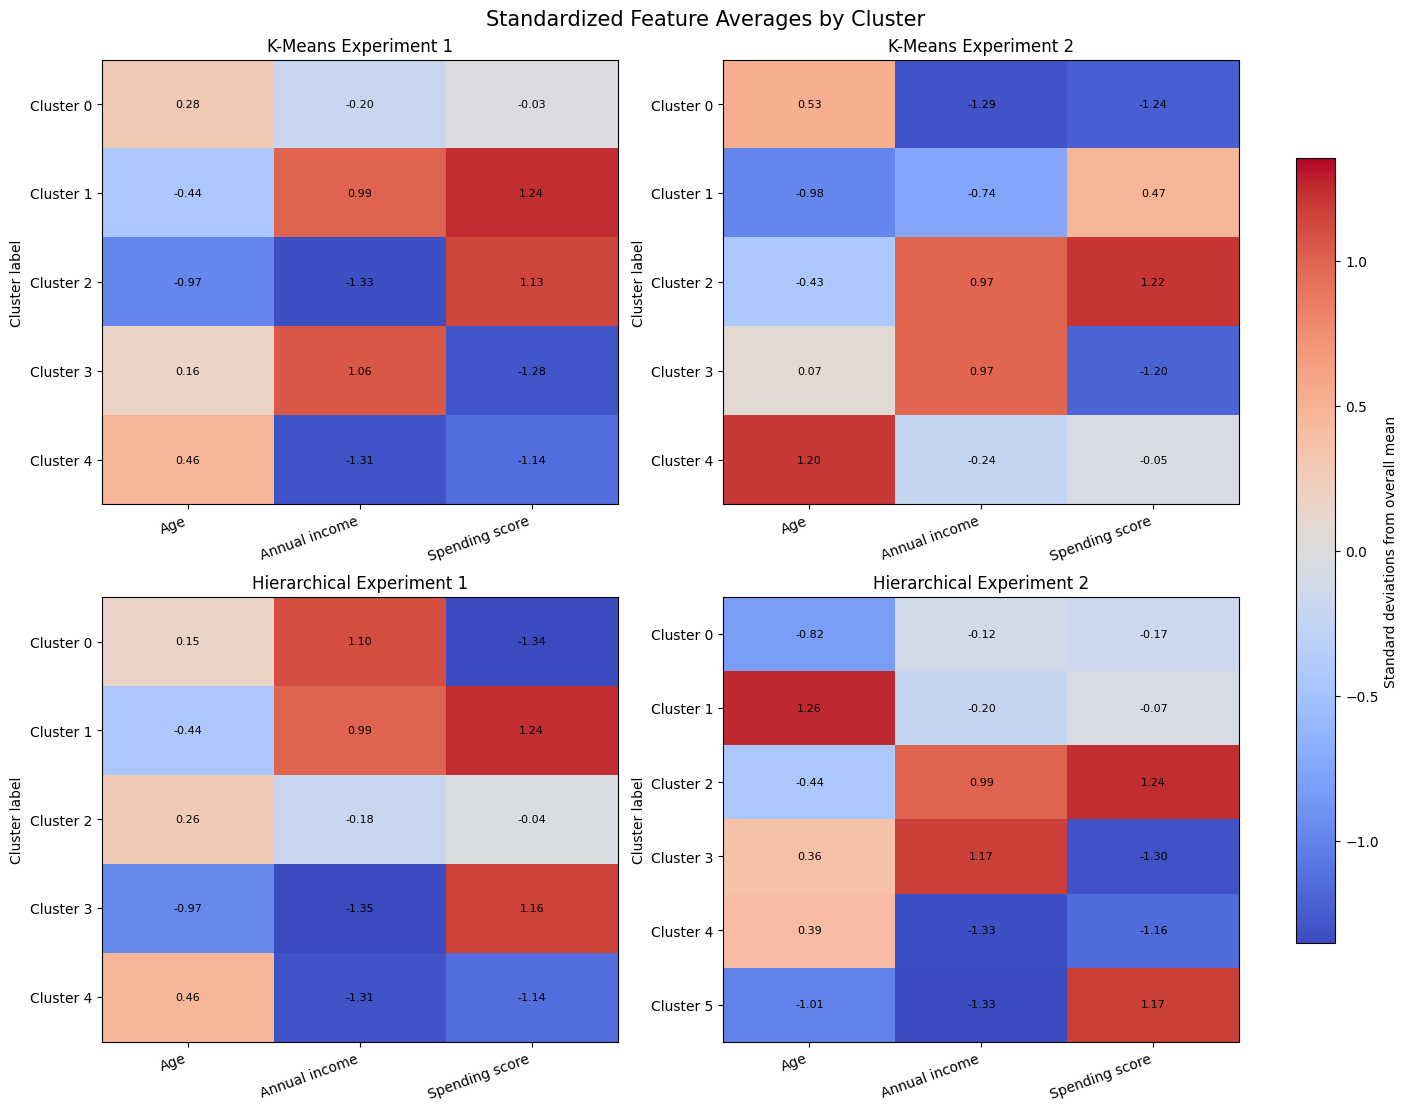

In [4]:
scaler = StandardScaler().fit(customers[FEATURES])
standardized_profiles = {}

for experiment, profile in profiles.items():
    standardized_profiles[experiment] = pd.DataFrame(
        scaler.transform(profile[FEATURES]),
        index=profile.index,
        columns=FEATURES,
    )

color_limit = max(
    1.0,
    max(float(values.abs().to_numpy().max()) for values in standardized_profiles.values()),
)
fig, axes = plt.subplots(2, 2, figsize=(14, 11), constrained_layout=True)

for ax, (experiment, values) in zip(axes.flat, standardized_profiles.items()):
    image = ax.imshow(values.to_numpy(), cmap="coolwarm", vmin=-color_limit, vmax=color_limit, aspect="auto")
    ax.set_title(experiment)
    ax.set_xticks(range(len(FEATURES)), ["Age", "Annual income", "Spending score"], rotation=20, ha="right")
    ax.set_yticks(range(len(values.index)), [f"Cluster {cluster}" for cluster in values.index])
    ax.set_ylabel("Cluster label")

    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            ax.text(column, row, f"{values.iloc[row, column]:.2f}", ha="center", va="center", fontsize=8)

fig.colorbar(image, ax=axes, label="Standard deviations from overall mean", shrink=0.8)
fig.suptitle("Standardized Feature Averages by Cluster", fontsize=15)
plt.show()

## 5. Which Characteristics Stand Out?

For each cluster, the features are ordered by the absolute standardized difference from the overall average. The largest differences describe which measured characteristics most distinguish that cluster from the full customer set. The simple descriptions below use the actual cluster averages and identify values as above or below the overall average.

In [5]:
FEATURE_LABELS = {
    "Age": "age",
    "Annual Income (k$)": "annual income",
    "Spending Score (1-100)": "spending score",
}

for experiment, profile in profiles.items():
    deviations = standardized_profiles[experiment]
    print(f"\n{experiment}")
    for cluster, averages in profile.iterrows():
        cluster_deviation = deviations.loc[cluster]
        distinguishing = cluster_deviation.abs().sort_values(ascending=False).index[:2]
        descriptions = []

        for feature in FEATURES:
            difference = averages[feature] - overall_averages[feature]
            if abs(cluster_deviation[feature]) < 0.05:
                relative = "close to the overall average"
            elif difference > 0:
                relative = "above the overall average"
            else:
                relative = "below the overall average"
            descriptions.append(f"{FEATURE_LABELS[feature]} {relative} ({averages[feature]:.1f})")

        standout_labels = [FEATURE_LABELS[feature] for feature in distinguishing]
        count = int(averages["Number of customers"])
        print(
            f"  Cluster {cluster} ({count} customers): {', '.join(descriptions)}. "
            f"Largest relative differences: {', '.join(standout_labels)}."
        )


K-Means Experiment 1
  Cluster 0 (81 customers): age above the overall average (42.7), annual income below the overall average (55.3), spending score close to the overall average (49.5). Largest relative differences: age, annual income.
  Cluster 1 (39 customers): age below the overall average (32.7), annual income above the overall average (86.5), spending score above the overall average (82.1). Largest relative differences: spending score, annual income.
  Cluster 2 (22 customers): age below the overall average (25.3), annual income below the overall average (25.7), spending score above the overall average (79.4). Largest relative differences: annual income, spending score.
  Cluster 3 (35 customers): age above the overall average (41.1), annual income above the overall average (88.2), spending score below the overall average (17.1). Largest relative differences: spending score, annual income.
  Cluster 4 (23 customers): age above the overall average (45.2), annual income below the 

## 6. Compare Cluster Assignments

Adjusted Rand Index (ARI) compares two groupings while accounting for arbitrary cluster numbering: 1 indicates identical partitions, while values near 0 indicate little agreement beyond chance. The contingency tables show the actual overlap between labels; row and column cluster IDs are not assumed to represent the same type of customer.

In [6]:
comparison_pairs = [
    ("K-Means Experiment 1", "Hierarchical Experiment 1", "Algorithms in Experiment 1"),
    ("K-Means Experiment 2", "Hierarchical Experiment 2", "Algorithms in Experiment 2"),
    ("K-Means Experiment 1", "K-Means Experiment 2", "Experiments within K-Means"),
    ("Hierarchical Experiment 1", "Hierarchical Experiment 2", "Experiments within Hierarchical Clustering"),
]

comparison_rows = []
for left, right, comparison in comparison_pairs:
    left_labels = assignments[left].set_index("CustomerID")["Cluster"].sort_index()
    right_labels = assignments[right].set_index("CustomerID")["Cluster"].sort_index()
    comparison_rows.append({
        "Comparison": comparison,
        "Grouping A": left,
        "Grouping B": right,
        "Adjusted Rand Index": adjusted_rand_score(left_labels, right_labels),
    })

comparison_table = pd.DataFrame(comparison_rows)
comparison_table.round({"Adjusted Rand Index": 3})

,Comparison,Grouping A,Grouping B,Adjusted Rand Index
0,Algorithms in Experiment 1,K-Means Experiment 1,Hierarchical Experiment 1,0.942
1,Algorithms in Experiment 2,K-Means Experiment 2,Hierarchical Experiment 2,0.696
2,Experiments within K-Means,K-Means Experiment 1,K-Means Experiment 2,0.584
3,Experiments within Hierarchical Clustering,Hierarchical Experiment 1,Hierarchical Experiment 2,0.673


In [7]:
for left, right, comparison in comparison_pairs[:2]:
    left_labels = assignments[left].set_index("CustomerID")["Cluster"].sort_index()
    right_labels = assignments[right].set_index("CustomerID")["Cluster"].sort_index()
    overlap = pd.crosstab(left_labels, right_labels, rownames=[left], colnames=[right])
    print(f"\nCustomer overlap: {comparison}")
    display(overlap)


Customer overlap: Algorithms in Experiment 1


Hierarchical Experiment 1,0,1,2,3,4
K-Means Experiment 1,,,,,
0,0,0,81,0,0
1,0,39,0,0,0
2,0,0,1,21,0
3,32,0,3,0,0
4,0,0,0,0,23



Customer overlap: Algorithms in Experiment 2


Hierarchical Experiment 2,0,1,2,3,4,5
K-Means Experiment 2,,,,,,
0,0,0,0,0,20,0
1,31,0,0,0,2,21
2,1,0,39,0,0,0
3,9,2,0,28,0,0
4,4,43,0,0,0,0


### How to Read the Comparison

Experiment 1 groups customers using income and spending score, while Experiment 2 also considers age. The Experiment 2 cluster count differs between the algorithms (five for K-Means and six for Hierarchical Clustering), so comparisons should focus on profile patterns and the label-invariant ARI rather than matching cluster numbers. The overlap tables show how customers are reassigned between methods for the same experiment.

## 7. Business Interpretation

The profiles can help a business describe groups in terms of their typical age, income, and spending score. For example, groups with comparatively high spending scores may be considered when designing engagement or loyalty offers, while groups with lower scores could motivate further research into barriers to engagement. Income and age patterns can help tailor communications or product analysis. These are possible uses of observed group descriptions, not evidence that a particular marketing action will cause a change in customer behavior.

## 8. Limitations

- These are descriptive explanations of cluster averages and assignment overlap; they do not explain why a customer behaves a certain way.
- A feature differing from the overall mean is not necessarily important to the clustering model. The standardized deviations are not causal estimates, predictive feature importance, or SHAP values.
- Cluster labels are arbitrary, and cluster counts and assignments depend on the selected features, scaling, algorithm, and chosen number of clusters.
- Averages can hide variation within each cluster, and the Mall Customers dataset contains only a limited set of demographic and spending variables.
- The groupings should be validated with additional data and business context before decisions are made.